## **#Importing necessary libraries for data manipulation**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib . pyplot as plt

### **#Load tables into the notebook**

In [ ]:
orders = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/orders.csv")
products = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/products.csv")
aisles= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/aisles.csv")
departments= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/departments.csv")
orderprodprior= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv")
orderprodtrain= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__train.csv")

# **#Confirming Table meanings**

1. Orders

In [ ]:
orders.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


ORDERS: the "element" being studied in this table is the individual order, and the row contains all measurements (variables) related to that single occurrence.One row represents a single customer order, which is a discrete transaction event.

2.Products

In [ ]:
products.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


PRODUCTS: The element being measured in this table is the individual product, and the row provides the complete set of measurements for that element. One row represents a single unique product or item in the organization's catalog.

3.Products_Prior

In [ ]:
orderprodprior.head()

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


ORDER_PRODUCTS_PRIOR: One row represents a single product included as an item within a specific order eg the first five rows all share the same order_id (2), demonstrating that order #2 contained at least five different products, with each product being described by its own distinct row in this table

4.Order Products Train

In [ ]:
orderprodtrain.head()

,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


Each row represents a specific product included in a specific order. This table acts as a detailed transaction list for the "train" dataset split, identifying which product_id was added to which order_id, the sequence in which it was added (add_to_cart_order), and whether it was a repeat purchase (reordered)

5.Aisles

In [ ]:
aisles.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


 Each row represents a unique aisle or product subcategory. With 134 total entries, this table serves as a lookup for categorical labels such as "vegetables" or "bakery," linked to a unique aisle_id

6.Departments

In [ ]:
departments.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


Each row represents a unique high-level product department. There are 21 total entries in this table, providing the categorical names for departments like "produce" or "dairy" corresponding to each department_id

**#Key Columns for Merging (Joining Tables)**


*  order_id: The primary link between the ORDERS table and the transaction tables (ORDER_PRODUCTS_PRIOR/_TRAIN)
*   product_id: Links the specific items in an order to their descriptive names and categories in the PRODUCTS table

*   aisle_id: Connects the PRODUCTS table to the AISLES table to get categorical aisle names
*   department_id: Connects the PRODUCTS table to the DEPARTMENTS table to get high-level category names




# **#BIVARIATE QUESTIONS**



1.   Is there a statistical association between the day of the week and the hour of the day when orders are placed?
2.   How does the distribution of time elapsed since the prior purchase (days_since_prior_order) vary across the different days of the week (order_dow) on which a customer chooses to shop?

3.   What is the nature and strength of the relationship between a customer’s cumulative number of orders (order_number) and the time elapsed since their previous purchase (days_since_prior_order)?








# **#Categorical VS Categorical**

To see if the outcome of one variable is related to the outcome of another.

In [ ]:
pd.crosstab(orders['order_dow'], orders['order_hour_of_day'])

order_hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
order_dow,,,,,,,,,,,,,,,,,,,,,
0,3936,2398,1409,963,813,1168,3329,12410,28108,40798,...,54552,53954,49463,39753,29572,22654,18277,14423,11246,6887
1,3674,1830,1105,748,809,1607,5370,16571,34116,51908,...,46764,46403,44761,36792,28977,22145,16281,11943,8992,5620
2,3059,1572,943,719,744,1399,4758,13245,24635,36314,...,37173,37469,37541,32151,26470,20084,15039,10653,8146,5358
3,2952,1495,953,654,719,1355,4562,12396,22553,32312,...,34773,35990,35273,30368,25001,19249,13795,10278,8242,5181
4,2642,1512,899,686,730,1330,4401,12493,21814,31409,...,33625,34222,34093,29378,24425,19350,14186,10796,8812,5645
5,3189,1672,1016,841,910,1574,4866,13434,24015,34232,...,37407,37508,35860,29955,24310,18741,13322,9515,7498,5265
6,3306,1919,1214,863,802,1136,3243,11319,22960,30839,...,38748,38093,35562,30398,24157,18346,13392,10501,8532,6087


Dominant Days and Hours


*   Sunday (Day 0) consistently shows the highest frequencies in the midday window, with a peak of 54,552 orders at Hour 14 (2:00 PM)
*   Monday (Day 1) follows closely, maintaining high volumes (e.g., 46,764 orders at Hour 14), which aligns with the finding that these two days represent the organization's peak weekly activity

*   Volume is most intense between Hour 14 (2:00 PM) and Hour 15 (3:00 PM)




Visualising

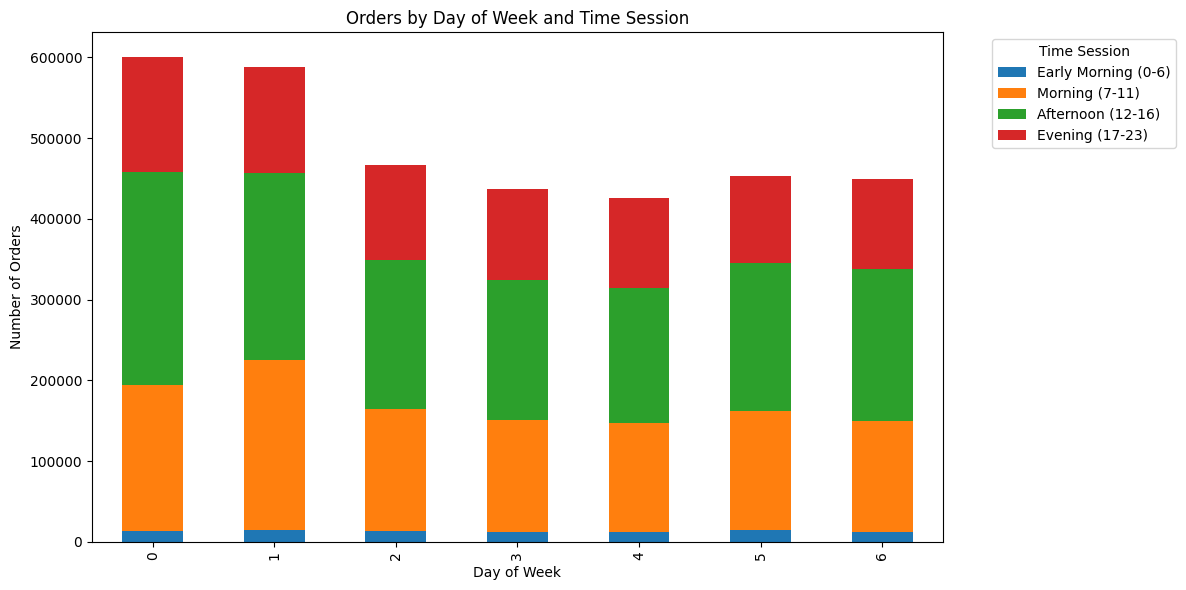

<Figure size 640x480 with 0 Axes>

In [ ]:
conditions = [
    (orders['order_hour_of_day'] >= 0) & (orders['order_hour_of_day'] <= 6),
    (orders['order_hour_of_day'] >= 7) & (orders['order_hour_of_day'] <= 11),
    (orders['order_hour_of_day'] >= 12) & (orders['order_hour_of_day'] <= 16),
    (orders['order_hour_of_day'] >= 17) & (orders['order_hour_of_day'] <= 23)
]
choices = ['Early Morning (0-6)', 'Morning (7-11)', 'Afternoon (12-16)', 'Evening (17-23)']
orders['order_time_session'] = np.select(conditions, choices, default='Unknown')

ct_grouped = pd.crosstab(orders['order_dow'], orders['order_time_session'])

session_order = ['Early Morning (0-6)', 'Morning (7-11)', 'Afternoon (12-16)', 'Evening (17-23)']
ct_grouped = ct_grouped[session_order]

ct_grouped.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.title("Orders by Day of Week and Time Session")
plt.legend(title='Time Session', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/DOW_by_TimeSession_CROSS.png", bbox_inches='tight')

The primary purpose of this visual is to explore if a statistical association exists between the two variables

Day 0 (Sunday) and Day 1 (Monday) are the dominant days for the organisation, while Day 4 (Thursday) represents the lowest point in weekly activity

* The total height of each bar represents the cumulative number of orders for that specific day.
* Bars have 4 segments representing a range in time of day

Limitations:

*   Perceptual Difficulty
*   Cognitive Overloading






Is there a statistical association between the day of the week and the hour of the day when orders are placed? YES

# **#Numerical VS Categorical**

In [ ]:
orders.groupby('order_dow')['days_since_prior_order'].mean()
orders.groupby('order_dow')['days_since_prior_order'].median()

,days_since_prior_order
order_dow,
0,8.0
1,8.0
2,8.0
3,7.0
4,7.0
5,7.0
6,7.0


How does the distribution of time elapsed since the prior purchase (days_since_prior_order) vary across the different days of the week (order_dow) on which a customer chooses to shop?

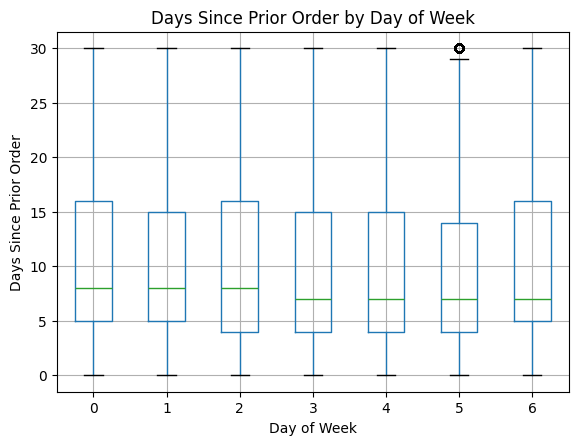

<Figure size 640x480 with 0 Axes>

In [ ]:
orders.boxplot(column='days_since_prior_order', by='order_dow')
plt.xlabel("Day of Week")
plt.ylabel("Days Since Prior Order")
plt.title("Days Since Prior Order by Day of Week")
plt.suptitle("")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/DOW_BOXPLOT.png", bbox_inches='tight')



*   Consistency of Central Location: The green median lines within each box show that the typical time elapsed since a prior purchase is remarkably consistent across all seven days, ranging between 7 and 8 days.

*   Uniform Dispersion:The Interquartile Range (IQR)—the height of the blue boxes—is nearly identical for every day, with the middle 50% of return visits generally occurring between 5 and 15 days after the previous order.


*   Positive Skewness : Most days exhibit slight positive skewness, indicated by the upper whiskers being longer than the lower whiskers and the median lines sitting slightly closer to the bottom of the boxes (Q1). This means a portion of customers take much longer than the 7-day average to return.
* Outlier Prescense: outlier on Day 5 (Friday) at the 30-day mark.



Limitations:

*   Lack of Volume Insight: shows the distribution of time but not the volume of transactions.
*   Cognitive Limits on Precision: does not provide the precise statistics (such as the exact mean or standard deviation) that a manager might need for high-stakes logistics or financial planning without referring to a secondary summary table.



How does the distribution of time elapsed since the prior purchase (days_since_prior_order) vary across the different days of the week (order_dow) on which a customer chooses to shop?

*   The distribution of time elapsed since the prior purchase varies very little across the different days of the week. The return shopping patterns are remarkably uniform.




# **#NUMERICAL VS NUMERICAL**

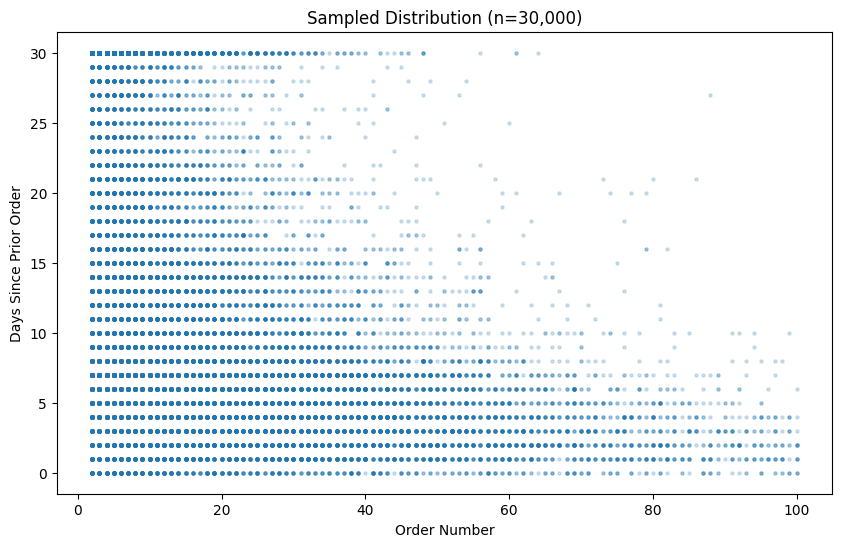

In [ ]:
# Randomly sample 30,000 rows
tmp_sampled = tmp.sample(n=30000, random_state=42)

plt.figure(figsize=(10, 6))
# Use very small markers (s=1) and low alpha (0.1 to 0.2)
plt.scatter(tmp_sampled['order_number'],
            tmp_sampled['days_since_prior_order'],
            alpha=0.2,
            s=5)

plt.xlabel("Order Number")
plt.ylabel("Days Since Prior Order")
plt.title("Sampled Distribution (n=30,000)")
plt.show()



*  Inverse (negative) relationship: as a customer’s cumulative number of orders (order_number) increases—indicating higher loyalty—the time elapsed since their previous purchase (days_since_prior_order) tends to decrease.
*   Nature of the Pattern:the "density" of the 30-day return window appears to thin out slightly for customers with very high order counts, supporting the idea of habit formation among power users



Limitation:
* Data capping

In [ ]:
tmp_sampled.corr()

,order_number,days_since_prior_order
order_number,1.000000,-0.364646
days_since_prior_order,-0.364646,1.000000


Correlation

* moderate negative linear relationship
* 13% of the variation in a customer's return time can be explained by how many orders they have placed previously. The remaining 87% of the variation is due to other "external" factors




**#REORDER BEHAVIOUR ANALYSIS**

In [ ]:
merged = orders.merge(
    orderprodprior[['order_id', 'reordered']],
    on='order_id',
    how='inner'
)
merged.groupby('order_dow')['reordered'].mean()

,reordered
order_dow,
0,0.585276
1,0.603843
2,0.589771
3,0.586272
4,0.590979
5,0.595470
6,0.574369


The use of reordered here is to move beyond simply counting sales to understanding customer loyalty and habit formation on a day-by-day basis.

Interpretation:
*  shows that the reorder rate is remarkably stable, ranging from approximately 57.4% to 60.4%. This means that in any given order, more than half of the items are products the customer has purchased before.

# **#Strongest Relationships and Key Insights**

Categorical–Categorical (Association):

*   There is a strong statistical association between the day of the week (order_dow) and the hour of the day (order_hour_of_day). While demand peaks during the "midday rush" (10 AM–4 PM) every day, Sunday at 2 PM represents the absolute operational "hot spot" with volume up to 65% higher than mid-week lows
*   Numerical–Categorical (Breakdown): The typical time between orders (days_since_prior_order) is remarkably uniform across all days of the week, with a consistent median return cycle of 7–8 days. This suggests that while the day affects volume, it does not influence individual customer cadence .



EDA LIMITATIONS:


*   Visual Complexity: Stacked bar charts with 24 hourly segments can reach cognitive limits, making precise comparisons of segment sizes difficult without a common baseline



***Insightful Reflection & Future Testing:***

EDA acts as the "magnifying glass" that informs the next steps of the Knowledge Discovery (KDD) process. These findings transition into future testing through:

*   Hypothesis Testing: Using ANOVA to determine if the mean return cycle differs significantly across high-volume versus low-volume departments.
*   Predictive Modeling: The loyalty-frequency association serves as a baseline feature for regression models aimed at forecasting a customer's specific "next purchase" date.
* Prescriptive Analytics: Operational "hot spots" identified in EDA provide the logic for optimized staffing models and delivery logistics.



# END OF T3

## **#Summary statistics for Numerical Variables**

**DAYS SINCE PRIOR ORDER**

---



In [ ]:
orders['days_since_prior_order'].describe()

,days_since_prior_order
count,3.214874e+06
mean,1.111484e+01
std,9.206737e+00
min,0.000000e+00
25%,4.000000e+00
50%,7.000000e+00
75%,1.500000e+01
max,3.000000e+01


Histogram

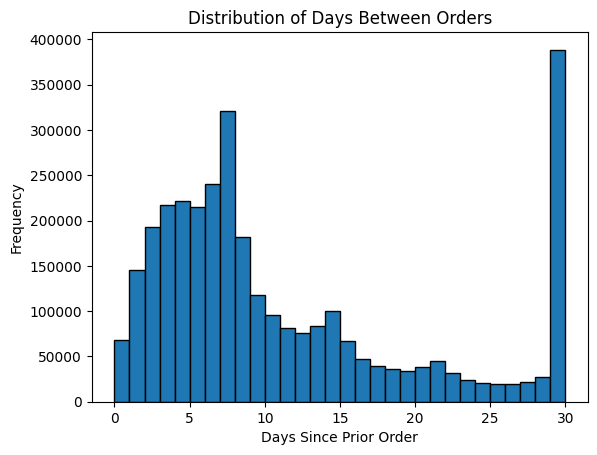

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['days_since_prior_order'].dropna(), bins=30, edgecolor='black')
plt.xlabel("Days Since Prior Order")
plt.ylabel("Frequency")
plt.title("Distribution of Days Between Orders")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/days_between_orders.png", bbox_inches='tight')

1. Notable Features:

-Prominent peak at the 7-day mark

  -Huge decline after day 7.

  -A secondary, smaller peak is visible around 14 to 15 days.
  
  -Massive spike at exactly 30 days, which represents the highest frequency in the entire dataset.

  

*ORDER NUMBER*

---



In [ ]:
orders['order_number' ].describe()

,order_number
count,3.421083e+06
mean,1.715486e+01
std,1.773316e+01
min,1.000000e+00
25%,5.000000e+00
50%,1.100000e+01
75%,2.300000e+01
max,1.000000e+02


Histogram

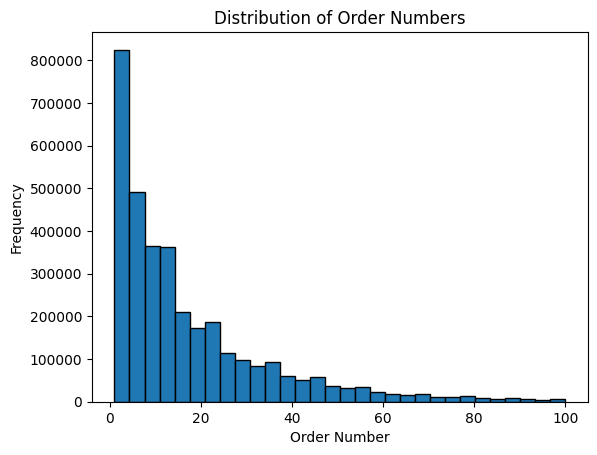

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['order_number'].dropna(),bins=30, edgecolor='black')
plt.xlabel("Order Number")
plt.ylabel("Frequency")
plt.title("Distribution of Order Numbers")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/order_num.png", bbox_inches='tight')

1. Overall Shape: Highly Positively Skewed.

2. Notable Features:
  -The highest frequency occurs at the very beginning of the X-axis (order numbers 1–5)
  -There is a steady, non-linear decline in frequency as the order number increases.

**ORDER HOUR OF DAY**

---



In [ ]:
orders['order_hour_of_day'].describe()

,order_hour_of_day
count,3.421083e+06
mean,1.345202e+01
std,4.226088e+00
min,0.000000e+00
25%,1.000000e+01
50%,1.300000e+01
75%,1.600000e+01
max,2.300000e+01


Histogram

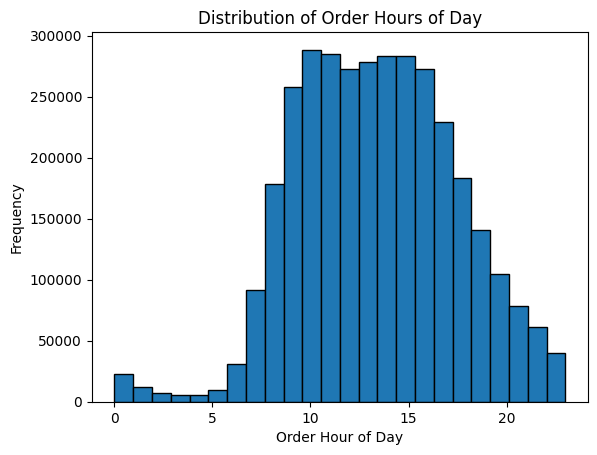

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['order_hour_of_day'].dropna(), bins=24, edgecolor='black')
plt.xlabel("Order Hour of Day")
plt.ylabel("Frequency")
plt.title("Distribution of Order Hours of Day")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/order_hr_of_day.png", bbox_inches='tight')

1. Overall Shape: Approximately Symmetric and Unimodal
2. Notable Features:
  -Ordering remains at its highest and most stable around 10:00–16:00
  -Peak Hour at 10:00
  -There is morning dormancy between 1 am and 5am

## **#CATEGORICAL DATA UNIVARIATE ANALYSIS**

ORDER DAY OF WEEK

---



Frequency count

In [ ]:
orders['order_dow'].value_counts()

,count
order_dow,
0,600905
1,587478
2,467260
5,453368
6,448761
3,436972
4,426339


Based on the frequency count it is clear day 0 has the highest frequency. Customers are most common during this day.

Visualisation

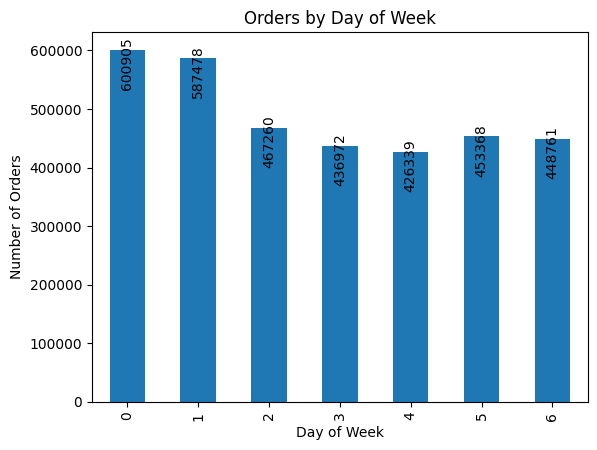

<Figure size 640x480 with 0 Axes>

In [ ]:
dow = orders['order_dow'].value_counts().sort_index().plot(kind='bar')
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.title("Orders by Day of Week")

# To add frequency labels inside the bars vertically
for p in dow.patches:
    dow.annotate(str(p.get_height()), (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, -10), textcoords='offset points', rotation=90, color='black')

plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/orders_by_day_of_week.png", bbox_inches='tight')

Dominant Categories (Peak Activity): The most frequent ordering days are Day 0 (Sunday) with 600,905 orders and Day 1 (Monday) with 587,478 orders. These two days represent the absolute peak of customer activity for the organisation.

Rare Categories (Lowest Activity): The days with the lowest transaction volume are Day 4 (Thursday) with 426,339 orders and Day 3 (Wednesday) with 436,972 orders. These mid-week days represent the "valleys" in the company's weekly operational cycle.

These results align with standard expectations for a grocery or shipment service. Typically, consumers use the weekend (Sunday) and the start of the work week (Monday) to restock their households for the coming days. Conversely, activity often dips mid-week before rising again as the next weekend approaches.

This information answers the question  "On which day of the week do customers shop most frequently?"
Sunday stands out as the most frequented day. Management should use this information for staffing and logistics planning, ensuring maximum warehouse personnel and delivery drivers are available at the start of the week to handle the surge in demand.

Eval Set

---



**"What is the proportional distribution of orders across the 'prior', 'train', and 'test' dataset partitions?"**

Frequency count

In [ ]:
orders['eval_set'].value_counts()

,count
eval_set,
prior,3214874
train,131209
test,75000


*   Prior: Approximately 93.97%
*   Train: Approximately 3.84%

*   Test: Approximately 2.19%


Visualisation

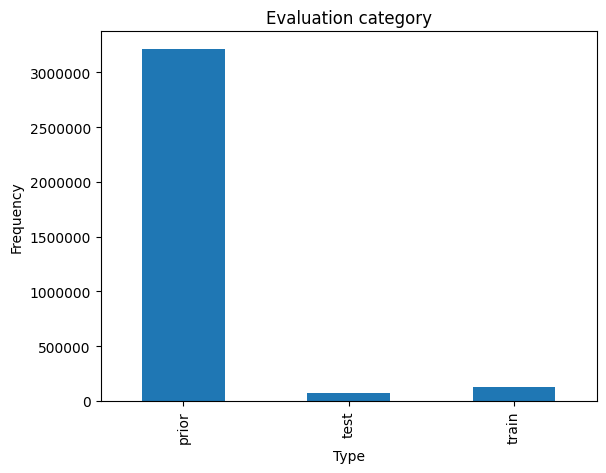

<Figure size 640x480 with 0 Axes>

In [ ]:
orders['eval_set'].value_counts().sort_index().plot(kind='bar')
plt.xlabel("Type")
plt.ylabel("Frequency")
plt.title("Evaluation category")
plt.ticklabel_format(style='plain', axis='y')
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/eval_freq.png", bbox_inches='tight')

Dominant Category: The "prior" set is the overwhelmingly dominant category, containing 3,214,874 orders. Visually, the bar for "prior" towers over the other two categories, representing the vast majority of the company's historical data.

Rare Categories: The "train" and "test" categories are relatively rare. The "train" set contains 131,209 orders, while the "test" set is the smallest with 75,000 orders.

These results align perfectly with standard expectations for the Knowledge Discovery (KDD) process and predictive modelling.
It is expected that the "prior" set be the largest because it is used for descriptive analytics to establish stable behavioral baselines for customers—such as identifying peak hours and typical time between orders—before any modeling begins.


**#CHECK MISSING VALUES**

In [ ]:
orders.isna().sum().sort_values(ascending=False)

,0
days_since_prior_order,206209
user_id,0
order_id,0
eval_set,0
order_number,0
order_dow,0
order_hour_of_day,0


In [ ]:
aisles.isna().sum().sort_values(ascending=False)

,0
aisle_id,0
aisle,0


In [ ]:
departments.isna().sum().sort_values(ascending=False)

,0
department_id,0
department,0


In [ ]:
orderprodprior.isna().sum().sort_values(ascending=False)

,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


In [ ]:
orderprodtrain.isna().sum().sort_values(ascending=False)

,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


In [ ]:
products.isna().sum().sort_values(ascending=False)

,0
product_id,0
product_name,0
aisle_id,0
department_id,0


**#DATA DICTIONARY**

In [ ]:
variables_data = {
    'Table': ['ORDERS', 'ORDERS', 'ORDERS', 'ORDERS', 'ORDERS', 'ORDERS',
              'PRODUCTS', 'PRODUCTS', 'PRODUCTS', 'AISLES',
              'DEPARTMENTS', 'ORDER_PRODUCTS_PRIOR', 'ORDER_PRODUCTS_PRIOR'],
    'Column': ['user_id', 'order_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day',
               'product_id', 'product_name', 'aisle_id', 'aisle',
               'department', 'order_id', 'product_id'],
    'Meaning': [
        'Unique identifier for each customer',
        'Unique identifier for each order',
        'Indicator of whether this order is in the training, test, or prior datasets',
        'The sequence order number for this user (1st order, 2nd order, etc.)',
        'Day of week when the order was placed (0-6, where 0=Sunday)',
        'Hour of the day when the order was placed (0-23)',
        'Unique identifier for each product',
        'Name/description of the product',
        'Unique identifier for the aisle category',
        'Name of the aisle/subcategory',
        'Name of the product department',
        'References the order that contains product items',
        'References the product that was ordered'
    ],
    'Data Type': [
        'Integer (int64)',
        'Integer (int64)',
        'String/Categorical',
        'Integer (int64)',
        'Integer (int64)',
        'Integer (int64)',
        'Integer (int64)',
        'String/Text',
        'Integer (int64)',
        'String/Categorical',
        'String/Categorical',
        'Integer (int64)',
        'Integer (int64)'
    ],
    'Notes': [
        'Ranges from 0 to maximum user ID; unique per customer',
        'Unique order identifier; foreign key in ORDER_PRODUCTS tables',
        'Values: "prior", "train", "test" - indicates dataset split',
        'Sequential numbering starting from 1 for each user',
        'Integer 0-6 representing days; useful for day-of-week analysis',
        'Integer 0-23 in 24-hour format; useful for temporal analysis',
        'Unique product identifier; links to PRODUCTS table',
        'Product description/label; text-based information',
        'Foreign key linking to AISLES table',
        'Subcategory of products (e.g., "vegetables", "bakery")',
        'High-level product category (e.g., "produce", "dairy")',
        'Foreign key to ORDERS table; enables linking orders to products',
        'Foreign key to PRODUCTS table; identifies which product was purchased'
    ]
}

# Creating DataFrame
variable_table = pd.DataFrame(variables_data)

# For Displaying the table
print("=" * 150)
print("INSTACART DATASET: VARIABLE DESCRIPTION TABLE")
print("=" * 150)
print(variable_table.to_string(index=False))
print("=" * 150)

INSTACART DATASET: VARIABLE DESCRIPTION TABLE
               Table            Column                                                                     Meaning          Data Type                                                                 Notes
              ORDERS           user_id                                         Unique identifier for each customer    Integer (int64)                 Ranges from 0 to maximum user ID; unique per customer
              ORDERS          order_id                                            Unique identifier for each order    Integer (int64)         Unique order identifier; foreign key in ORDER_PRODUCTS tables
              ORDERS          eval_set Indicator of whether this order is in the training, test, or prior datasets String/Categorical            Values: "prior", "train", "test" - indicates dataset split
              ORDERS      order_number        The sequence order number for this user (1st order, 2nd order, etc.)    Integer (int64)     

**#INTERIM COLAB**

In [ ]:
orders.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/orders.csv", index=False)
products.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/products.csv", index=False)
aisles.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/aisles.csv", index=False)
departments.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/departments.csv", index=False)
orderprodprior.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv", index=False)
orderprodtrain.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__train.csv", index=False)

**#MARKDOWN Description**

1.The Dataset represents data of a Schipment company with supplies such as PlugTech which sells refurbished Data.


2.-Customer Segmentation: Managers can use Cluster Analysis to group customers based on which Aisles or Departments they frequent, allowing for targeted promotional campaigns
-Departmental Staffing: Descriptive analytics on Orders can highlight peak times for specific Departments, helping managers determine optimal staffing levels to handle order surges
-Demand Forecasting: The company can use time-series analysis on prior orders to forecast consumption of fast-moving products, ensuring the right amount of inventory is stocked to avoid stock-outs

3. Descriptive analytics:
   ORDERS Table, PRODUCTS, AISLES,ORDER_PRODUCTS_PRIOR Table and DEPARTMENTS Tables

   Predictive Analytics:
   ORDER_PRODUCTS_PRIOR and ORDER_PRODUCTS_TRAIN Tables

   Prescriptive Analytics:
   ORDERS, PRODUCTS, AISLES, DEPARTMENTS